# Exercice 1 — Régression : prédire le salaire selon l'ancienneté et l'expertise

Modèle de régression linéaire multiple :

$$\text{Salaire} = w_1 \cdot \text{Ancienneté} + w_2 \cdot \text{Expertise} + b$$

Données fictives générées selon : Salaire = 4000 + 600 × Ancienneté + 1500 × Expertise + Bruit (en DH).

## 1. Générer les données

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Nombre de salariés
n = 300

# Ancienneté : de 0 à 20 ans
anciennete = torch.randint(0, 21, (n, 1)).float()

# Expertise : de 1 à 5
expertise = torch.randint(1, 6, (n, 1)).float()

# Variations aléatoires des salaires
bruit = torch.randn(n, 1) * 500

# Salaire mensuel en DH
salaires = 4000 + 600 * anciennete + 1500 * expertise + bruit

# Matrice des entrées : dimensions (300, 2)
X = torch.cat([anciennete, expertise], dim=1)

# Sortie : dimensions (300, 1)
y = salaires

for i in range(5):
    print(
        f"Ancienneté : {X[i, 0].item():.0f} ans | "
        f"Expertise : {X[i, 1].item():.0f}/5 | "
        f"Salaire : {y[i, 0].item():.2f} DH"
    )

Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH


### Travail demandé : dimensions, salaire moyen, nuage de points

In [2]:
print("Dimensions de X :", X.shape)   # (300, 2)
print("Dimensions de y :", y.shape)   # (300, 1)
print(f"Salaire moyen : {y.mean().item():.2f} DH")

Dimensions de X : torch.Size([300, 2])
Dimensions de y : torch.Size([300, 1])
Salaire moyen : 15010.55 DH


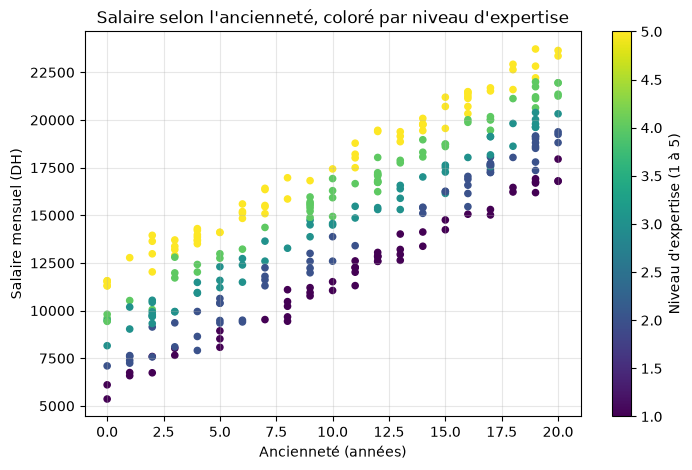

In [3]:
plt.figure(figsize=(8, 5))
nuage = plt.scatter(X[:, 0], y[:, 0], c=X[:, 1], cmap="viridis", s=20)
plt.colorbar(nuage, label="Niveau d'expertise (1 à 5)")
plt.xlabel("Ancienneté (années)")
plt.ylabel("Salaire mensuel (DH)")
plt.title("Salaire selon l'ancienneté, coloré par niveau d'expertise")
plt.grid(True, alpha=0.3)
plt.show()

On voit 5 « bandes » parallèles : à ancienneté égale, chaque niveau d'expertise décale le salaire vers le haut,
et la pente (effet de l'ancienneté) est la même pour tous les niveaux → une relation linéaire additive.

## 2. Séparer et préparer les données

80 % entraînement / 20 % test. Entrées standardisées avec les statistiques **du jeu d'entraînement** ; salaires en milliers de DH.

In [4]:
indices = torch.randperm(n)
limite = int(0.8 * n)

train_indices = indices[:limite]
test_indices = indices[limite:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices] / 1000
y_test = y[test_indices] / 1000

# Statistiques calculées uniquement sur le jeu d'entraînement
moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)

X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

print("Train :", X_train_norm.shape, "| Test :", X_test_norm.shape)
print("Moyenne d'entraînement :", moyenne)
print("Écart-type d'entraînement :", ecart_type)

Train : torch.Size([240, 2]) | Test : torch.Size([60, 2])
Moyenne d'entraînement : tensor([[10.5375,  3.1542]])
Écart-type d'entraînement : tensor([[6.1228, 1.4396]])


## 3. Construire et entraîner le modèle

In [5]:
# Deux variables d'entrée et une sortie
model = nn.Linear(2, 1)

# Erreur quadratique moyenne
criterion = nn.MSELoss()

optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

historique = []

model.train()

for epoch in range(500):
    # 1. Réinitialiser les gradients
    optimizer.zero_grad()

    # 2. Prédire les salaires
    predictions = model(X_train_norm)

    # 3. Calculer la perte
    loss = criterion(predictions, y_train)

    # 4. Calculer les gradients
    loss.backward()

    # 5. Mettre à jour les paramètres
    optimizer.step()

    historique.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(f"Époque {epoch + 1} | Perte : {loss.item():.4f}")

Époque 100 | Perte : 0.2391
Époque 200 | Perte : 0.2391
Époque 300 | Perte : 0.2391
Époque 400 | Perte : 0.2391
Époque 500 | Perte : 0.2391


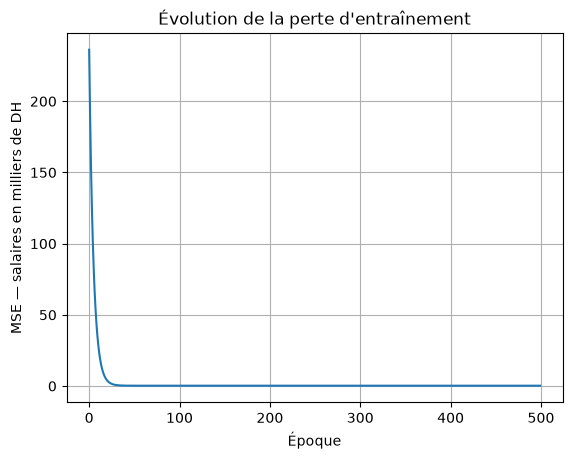

In [6]:
plt.plot(historique)
plt.xlabel("Époque")
plt.ylabel("MSE — salaires en milliers de DH")
plt.title("Évolution de la perte d'entraînement")
plt.grid()
plt.show()

## 4. Évaluer les prédictions

In [7]:
model.eval()

with torch.no_grad():
    predictions_test = model(X_test_norm)

    # Conversion en DH
    predictions_dh = predictions_test * 1000
    salaires_reels_dh = y_test * 1000

    mae = (predictions_dh - salaires_reels_dh).abs().mean()

print(f"Erreur absolue moyenne : {mae.item():.2f} DH")

Erreur absolue moyenne : 381.64 DH


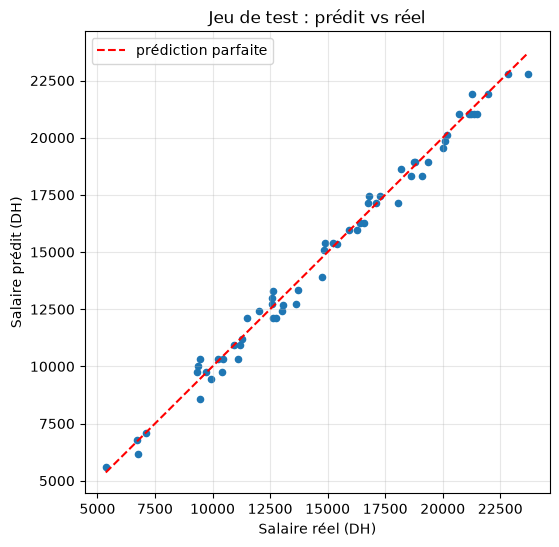

In [8]:
plt.figure(figsize=(6, 6))
plt.scatter(salaires_reels_dh, predictions_dh, s=20)
limites = [salaires_reels_dh.min().item(), salaires_reels_dh.max().item()]
plt.plot(limites, limites, "r--", label="prédiction parfaite")
plt.xlabel("Salaire réel (DH)")
plt.ylabel("Salaire prédit (DH)")
plt.title("Jeu de test : prédit vs réel")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Interprétation : la MAE indique de combien de DH les prédictions s'écartent, en moyenne, des salaires réels.
Le bruit a un écart-type de 500 DH ; pour une loi normale, l'écart absolu moyen correspondant est 500 × √(2/π) ≈ 400 DH.
Une MAE proche de 400 DH signifie donc que le modèle a capté toute la partie prévisible du salaire.

## 5. Prédire le salaire d'un nouveau salarié (7 ans, expertise 4/5)

In [9]:
nouveau_salarie = torch.tensor([[7.0, 4.0]])

# Appliquer la même normalisation qu'à l'entraînement
nouveau_salarie_norm = (nouveau_salarie - moyenne) / ecart_type

with torch.no_grad():
    salaire_predit = model(nouveau_salarie_norm) * 1000   # retour en DH

print(f"Salaire estimé : {salaire_predit.item():.2f} DH")
print("Valeur sans bruit : 4000 + 600*7 + 1500*4 = 14200 DH")

Salaire estimé : 14201.94 DH
Valeur sans bruit : 4000 + 600*7 + 1500*4 = 14200 DH


## Questions complémentaires

### Retrouver les coefficients en unités d'origine

Le modèle apprend sur des entrées standardisées et des salaires en milliers de DH :

$$\frac{\hat{y}}{1000} = a_1 \frac{x_1 - \mu_1}{\sigma_1} + a_2 \frac{x_2 - \mu_2}{\sigma_2} + c$$

En développant :

$$w_i = 1000 \cdot \frac{a_i}{\sigma_i} \qquad b = 1000 \cdot \left(c - \frac{a_1\mu_1}{\sigma_1} - \frac{a_2\mu_2}{\sigma_2}\right)$$

In [10]:
a = model.weight.detach()[0]        # (a1, a2)
c = model.bias.detach()[0]
mu, sigma = moyenne[0], ecart_type[0]

w = 1000 * a / sigma
b = 1000 * (c - (a * mu / sigma).sum())

print(f"w1 (effet d'une année d'ancienneté) : {w[0].item():8.1f} DH   (attendu ≈ 600)")
print(f"w2 (effet d'un niveau d'expertise)  : {w[1].item():8.1f} DH   (attendu ≈ 1500)")
print(f"b  (salaire de base)                : {b.item():8.1f} DH   (attendu ≈ 4000)")

w1 (effet d'une année d'ancienneté) :    592.7 DH   (attendu ≈ 600)
w2 (effet d'un niveau d'expertise)  :   1490.7 DH   (attendu ≈ 1500)
b  (salaire de base)                :   4090.3 DH   (attendu ≈ 4000)


### Effet du bruit sur la précision (expérience)

On régénère les données avec plusieurs niveaux de bruit et on mesure la MAE de test.

In [11]:
def experience(ecart_bruit, graine=0):
    g = torch.Generator().manual_seed(graine)
    anc = torch.randint(0, 21, (n, 1), generator=g).float()
    exp = torch.randint(1, 6, (n, 1), generator=g).float()
    sal = 4000 + 600 * anc + 1500 * exp + torch.randn(n, 1, generator=g) * ecart_bruit
    Xe = torch.cat([anc, exp], dim=1)
    idx = torch.randperm(n, generator=g)
    tr, te = idx[:limite], idx[limite:]
    mu_e, sd_e = Xe[tr].mean(0, keepdim=True), Xe[tr].std(0, keepdim=True)
    m = nn.Linear(2, 1)
    opt = torch.optim.SGD(m.parameters(), lr=0.05)
    for _ in range(500):
        opt.zero_grad()
        perte = criterion(m((Xe[tr] - mu_e) / sd_e), sal[tr] / 1000)
        perte.backward()
        opt.step()
    with torch.no_grad():
        return ((m((Xe[te] - mu_e) / sd_e) * 1000 - sal[te]).abs().mean().item())


for e in [0, 250, 500, 1000, 2000]:
    print(f"bruit σ = {e:4d} DH -> MAE test = {experience(e):7.1f} DH")

bruit σ =    0 DH -> MAE test =     0.0 DH
bruit σ =  250 DH -> MAE test =   202.9 DH


bruit σ =  500 DH -> MAE test =   405.8 DH


bruit σ = 1000 DH -> MAE test =   811.5 DH
bruit σ = 2000 DH -> MAE test =  1623.0 DH


### Réponses

**À expertise constante, quel est l'effet d'une année d'ancienneté supplémentaire ?**
Le salaire augmente de $w_1$, environ **600 DH par an** (valeur retrouvée ci-dessus). Le modèle est linéaire : cet effet est le même quels que soient l'ancienneté et le niveau d'expertise.

**Pourquoi la perte ne devient-elle pas exactement nulle ?**
À cause du **bruit** : il représente des variations individuelles qui ne dépendent ni de l'ancienneté ni de l'expertise. Le modèle ne peut pas les prévoir. La perte minimale atteignable est la variance du bruit : (500 DH)² = 0.25 en (milliers de DH)². C'est bien la valeur vers laquelle tend la courbe de perte.

**Le modèle est-il fiable pour une ancienneté de 40 ans ?**
Non, pas forcément. Les données couvrent seulement 0 à 20 ans. Prédire à 40 ans est une **extrapolation** : le modèle prolonge la droite (≈ 4000 + 600 × 40 + ...), mais rien ne garantit que la relation reste linéaire au-delà (plafond de grille salariale, poste différent, etc.). Le calcul se fait sans erreur, mais la validité du résultat n'est pas vérifiée par les données.

**Quel effet aurait une augmentation du bruit sur la précision ?**
L'expérience ci-dessus le montre : la MAE augmente à peu près **proportionnellement** à l'écart-type du bruit (≈ 0.8 × σ). L'erreur irréductible grandit, et les coefficients estimés deviennent moins précis avec seulement 240 exemples d'entraînement. Avec un bruit nul, le modèle retrouve presque exactement la règle (MAE proche de 0).

**Remarque sur l'expertise.** La traiter comme une note numérique suppose que chaque niveau ajoute le même montant (+1500 DH). Avec des données réelles, on pourrait vérifier cette hypothèse en encodant l'expertise en **one-hot**, c'est-à-dire une variable par niveau.